LangGraph is a flowchart builder for AI workflows. Instead of forcing your AI to run in a straight line (Step 1 -> Step 2 -> Step 3), LangGraph lets you build loops (retrying or calling tools multiple times), if/else decision branches, saved conversation memory, and human approval pauses.

####Step 1: Why Do We Even Need LangGraph?
When you use plain LangChain (chains using the | pipe), your code runs in a strict straight line:Prompt -> LLM -> Output

That works for simple Q&A, but it fails when you build real AI agents because real agents need:

Loops: Ask a tool for data $\rightarrow$ check the result $\rightarrow$ if it's not enough, search again. (A straight-line chain cannot loop backward.)

Decisions (if / else): Look at the user's question $\rightarrow$ if it needs Google search, go to Search; if it's a normal greeting, answer directly.

Memory & Pauses: Save the exact state after every step so the agent remembers past turns or pauses to ask a human for approval.

LangGraph solves this by letting you build your AI workflow as a Graph (a flowchart with boxes and arrows).

####Step 2: The 3 Core Parts of Every LangGraph Program

Every single LangGraph app—whether tiny or huge—is built from just 3 things:

State (TypedDict) — The shared dictionary passed from step to step.

Nodes (Python Functions) — The boxes in your flowchart. Each box reads State, does one job, and updates State.

Edges (add_edge / add_conditional_edges) — The arrows connecting one box to the next.

####Step 3: Deep Dive into State and Reducers (add_messages)

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

What is happening here?

State is just a Python dictionary ({"messages": [...]}) that travels through the entire graph.

Every node receives state as an input parameter and returns a dictionary to update it.

Why do we write Annotated[list, add_messages] instead of just messages: list?

Without add_messages: If state["messages"] has ["Hi"] and a node returns {"messages": ["Hello"]}, LangGraph replaces the old list—so ["Hi"] gets deleted and only ["Hello"] remains.

With add_messages: add_messages is a reducer (a merge rule). It tells LangGraph: "Do not overwrite the old list—append the new message to the end of it."

Result: ["Hi", "Hello"]. Both stay saved.

Step 4: Building Graph #1 — Simple Chatbot (START -> chatbot -> END)
This is the very first graph Krish builds:

In [2]:
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END

load_dotenv(override=True)
llm = init_chat_model("google_genai:gemini-3.5-flash-lite")

# 1. Node: Takes current State, calls LLM, returns new message
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

# 2. Graph Builder: Add nodes and arrows
builder = StateGraph(State)
builder.add_node("chatbot", chatbot)

builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

# 3. Compile into a runnable graph
graph = builder.compile()

Dry run when you call graph.invoke({"messages": [("user", "Hi")]}):

START puts [HumanMessage("Hi")] into state["messages"].

The arrow START -> "chatbot" runs chatbot(state).

Gemini replies "Hello! How can I help?", and add_messages appends it to state["messages"].

The arrow "chatbot" -> END stops the graph and returns the final state dictionary.

Step 5: Building Graph #2 — Adding Tools & if/else Routing (tools_condition)
Next, Krish gives the LLM external tools (like TavilySearch for web search and multiply for math) and adds a second box called ToolNode:

In [3]:
from langchain_core.tools import tool
from langchain_tavily import TavilySearch
from langgraph.prebuilt import ToolNode, tools_condition

@tool
def multiply(a: int, b: int) -> int:
    """Multiply a and b."""
    return a * b

tools = [TavilySearch(max_results=2), multiply]
llm_with_tools = llm.bind_tools(tools)

def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

In [4]:
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")

# Conditional Edge (if/else decision)
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
)

# Loop back from tools to the LLM!
builder.add_edge("tools", "tool_calling_llm")

graph = builder.compile()

Dry run when you ask "Multiply 5 by 2":
START -> tool_calling_llm: Gemini reads "Multiply 5 by 2".
 Because multiply is bound to it, Gemini outputs a tool call request (multiply(a=5, b=2)) instead of text.
 
 tools_condition (if/else check):Checks the last message in state["messages"].Does it contain a tool call? 
 Yes $\rightarrow$ routes to "tools". (If No $\rightarrow$ routes to END.)tools (ToolNode): Runs multiply(5, 2) in Python, gets 10, and appends ToolMessage("10") to state["messages"].
 
 tools -> tool_calling_llm (The Loop): Sends state["messages"] (now containing "10") back to Gemini.
 tool_calling_llm (Second pass): Gemini reads "10", writes "5 multiplied by 2 is 10", and emits no tool calls.tools_condition: Sees no tool calls $\rightarrow$ routes to END.

Step 6: Adding Memory (MemorySaver + thread_id)
By default, every graph.invoke(...) forgets previous conversations. To add memory:

Create memory = MemorySaver().

Pass it into compile: graph = builder.compile(checkpointer=memory).

Pass a thread_id whenever you run the graph:

In [5]:
config = {"configurable": {"thread_id": "1"}}
graph.invoke({"messages": [("user", "My name is Harshitha")]}, config=config)
graph.invoke({"messages": [("user", "What is my name?")]}, config=config)

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='0c43fd55-e14c-438a-bdd0-7f70b67d989a'),
  AIMessage(content=[{'type': 'text', 'text': "I don't know your name yet, as you haven't told me! What should I call you?", 'extras': {'signature': 'EpYBCpMBAWkUfROxN4lMMFWOTGUdKZHcU90wxyRtLkvTfXIf4h+rjfX+9A8aRWnOCa/KHM+wJjUpXA1RqSfbMPtHxJRnfYuhXoxxuEwLHxv4P8XSfoOrJEYcva3hiGZAxQVKmkI16taYaa4t3nY4Rk025rZ7ogrQqX6mXtSK98zmIJLr1GJ2FPB7BRR4SzkfYlHOasqNJ2yf'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'normalized_finish_reason': 'stop', 'model_provider': 'google_genai'}, id='lc_run--01a211c1-1a93-7618-860c-0bf4127d3c3d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1548, 'output_tokens': 23, 'total_tokens': 1571, 'input_token_details': {'cache_read': 0}})]}

How it works: After every single node finishes, LangGraph saves a snapshot of State under "thread_id": "1". On the next call with "thread_id": "1", it loads that saved State first so Gemini sees the entire conversation history. Changing "thread_id" to "2" starts a fresh conversation.

Step 7: Streaming (stream & astream)
Instead of waiting for invoke() to finish the entire graph, streaming lets you watch each node execute live:

stream_mode="updates": Yields only the new message produced by the node that just finished.

stream_mode="values": Yields the entire State dictionary (all messages so far) after each node finishes.

astream / astream_events: The async version (async for), which also lets you print tokens word-by-word as Gemini generates them.

Step 8: Human-in-the-Loop (interrupt + Command(resume=...))
When an agent needs human approval or input mid-way:

Inside a tool or node, call human_response = interrupt({"query": query}).

LangGraph freezes the graph right at that line, saves the State into MemorySaver, and exits back to you.

When the human is ready to answer, you resume the exact paused thread using:

In [7]:
graph.stream(Command(resume={"data": "Your human answer"}), config, stream_mode="values")

NameError: name 'Command' is not defined

LangGraph wakes up the graph, puts "Your human answer" into human_response, and finishes running the remaining nodes.

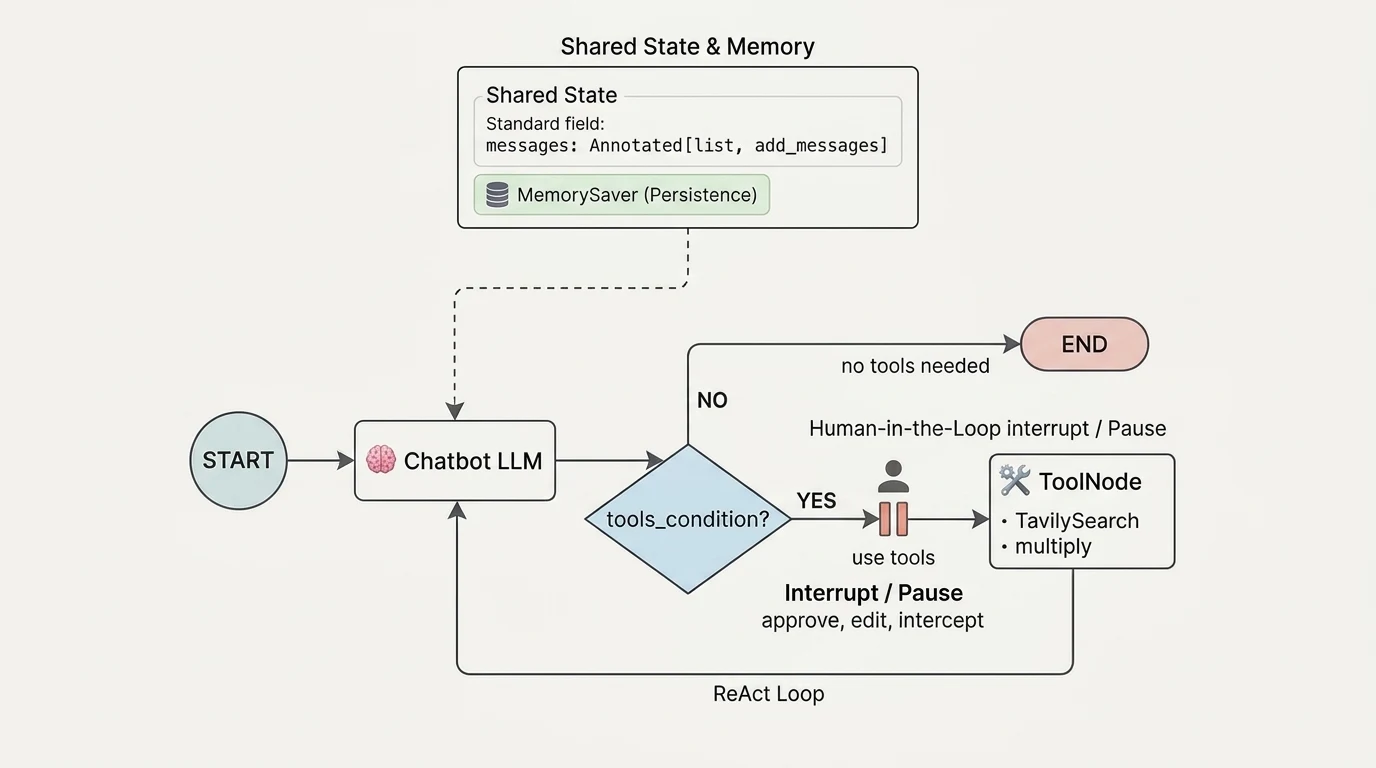